<a href="https://colab.research.google.com/github/erickcorrea3092/Antobiotics_Kurt_S_aureus/blob/main/3_Resumen_Kurt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Antecedentes

In [1]:
! pip install dash==3.2.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 26.0 MB/s eta 0:00:00


In [2]:
!pip install molplotly
!pip install rdkit
import molplotly

  Preparing metadata (setup.py) ... done
Discarding https://files.pythonhosted.org/packages/39/40/c0d86942ba668d975570a0fbd7fe4224445198a90a64ec6f0c1cd3bf2527/molplotly-1.1.8.tar.gz (from https://pypi.org/simple/molplotly/): Requested molplotly from https://files.pythonhosted.org/packages/39/40/c0d86942ba668d975570a0fbd7fe4224445198a90a64ec6f0c1cd3bf2527/molplotly-1.1.8.tar.gz has inconsistent version: expected '1.1.8', but metadata has '1.1.7'
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of molplotly to determine which version is compatible with other requirements. This could take a while.
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 11.4 MB/s eta 0:00:00
  Created wheel for molplotly: filename=molplotly-1.1.5-py3-none-any.whl size=13817 sha256=5a509ee84e51c2948c0c8a1763cc8420f1c776b77fab94300cb741dfb127e65d
  Stored in directory: /root/.cache/pip/wheels/ca

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import sklearn.metrics
import sklearn.pipeline
import sklearn.model_selection
import sklearn.feature_selection
from matplotlib import pyplot as plt
from sklearn.svm import SVR, OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedShuffleSplit
import plotly.express as px
import plotly.graph_objects as go
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from sklearn.linear_model import BayesianRidge
from sklearn.svm import NuSVR
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, StratifiedShuffleSplit

In [4]:
# sklearns
from sklearn.svm import SVR, OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedShuffleSplit
import plotly.express as px

In [5]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100

In [6]:
import rdkit
from rdkit.Chem import PandasTools

In [7]:
from rdkit.Chem import AllChem
#from rdkit import Chem
#from rdkit.Chem import Descriptors
#from rdkit.ML.Descriptors import MoleculeDescriptors
from rdkit.ML.Cluster import Butina
from rdkit import DataStructs
#from rdkit.Chem import PandasTools

# Globales

Definimos variables globales que nos ayudarán a tereminar la ejecución de nuestro código.

## Funciones auxiliares

In [8]:
# para los pasos de la pipeline que se han establecidos, regresa la pipeline que
# los considera a todos ellos, agregando el modelo de predicción recibido
# como parámetro
def get_pipeline(model=None):
  if model is None:
    extra_steps = []
  else:
    extra_steps = [("model", model)]
  pipeline = sklearn.pipeline.Pipeline(pipeline_steps + extra_steps)
  return pipeline

In [9]:
# nuestro método que regresa el splitter de validación cruzada que nos interesa
# (principalmente lo creé para poder hacer suffle=True fácilmente)
def get_cv_splitter():
  cv = sklearn.model_selection.KFold(n_splits=N_SPLITS, shuffle=True)
  return cv

In [10]:
# regresa el nombre de un modelo de sklearn
def model_name(model):
  name = model.__class__.__name__
  return name

In [11]:
# función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # Genera la matriz de distancia
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):
        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])
    #Cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

# Cargar datos

In [12]:
# descargamos data
! gdown --id 1cHM9neEhTOZ82UU9HaZkdGdlwE1d4SJT
! gdown --id 1wZp9pou63ElEYyGGjBeC2pDtscgRgCpj

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1cHM9neEhTOZ82UU9HaZkdGdlwE1d4SJT
To: /content/data.xlsx
100% 835k/835k [00:00<00:00, 9.86MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1wZp9pou63ElEYyGGjBeC2pDtscgRgCpj
To: /content/Actividad.xlsx
100% 9.40k/9.40k [00:00<00:00, 17.4MB/s]


In [13]:
# 1 Semilla para cosas random
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las features
MIN_VARIANCE = 0

# 3 Separación de datos
N_BINS=5 ##discretizer
N_SPLITS=10 ##splitter
TEST_SIZE=21/70 ##splitter

# 4 Algoritmo de escalamiento
# Otros que se pueden utilizar:StandardScaler(), MinMaxScaler() o Normalizer()
SCALER = StandardScaler()

# 5 Primer selector/transformador de features
feat_selector_model = RandomForestRegressor(n_estimators=49, min_samples_leaf=3, random_state=RANDOM_STATE)
FEAT_SELECTOR1 = SelectFromModel(feat_selector_model, max_features=22)

# 6 Segundo selector/transformador de features
n_pca = 8
FEAT_SELECTOR2 = PCA(n_components=n_pca, random_state=RANDOM_STATE)

# 7 Algoritmo de regresión
REGRESSOR = SVR(C=25, epsilon = 0.09)

# 8 Validación cruzada
METRICS = ["r2", "neg_mean_squared_error"]
CV_SPLITTER = KFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)


In [14]:
#Guardamos la data como una nueva variable
data = pd.read_excel("data.xlsx")
df_info = data[['Cmpd', 'SMILES']].copy() #has un dataframe que se llame df_info que incluya Cmpd y SMILES de data
#df_info

In [15]:
# cargamos data
df_x = data.copy()
#df_x = df_x.iloc[:, 1:]  # quitar "No."
df_x = df_x.select_dtypes("number")  # quitar non_numeric
df_y = pd.read_excel("Actividad.xlsx")

df_data = df_x.assign(activity=df_y)
#df_data

# Agrupación

In [16]:
#PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
PandasTools.AddMoleculeColumnToFrame(data,'SMILES', 'Structure')

In [17]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [18]:
## Vamos a obtener la identificación del cluster 'cluster_id'
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)
#_______________________________________________________________________
# Creamos un nuevo dataframe de nombre df_info, que tendrá el nombre del compuesto Cmpd, SMILES y el Cluster_number.
# En este nuevo dataframe agregaremos la información del cluster
#df_info = data[['Cmpd','SMILES']].copy() # Seleccionamos algunas columnas desde data
df_info['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
print('La forma de df_info es: ')
print(df_info.shape)
'Se obtuvieron '+ str(len(set(cluster_id))) + ' clusters'

  0%|          | 0/70 [00:00<?, ?it/s]

La forma de df_info es: 
(71, 3)


'Se obtuvieron 13 clusters'

#Separar datos


In [19]:
# dividimos train test con stratified
discretizer = sklearn.preprocessing.KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform")
splitter = StratifiedShuffleSplit(n_splits=N_SPLITS,test_size=TEST_SIZE, random_state=RANDOM_STATE)
y_discrete = discretizer.fit_transform(df_y.values)
split, split_test = next(splitter.split(df_x.values, y_discrete))
#Esta línea utiliza una comprensión de lista en Python, que es una forma compacta de crear listas.
fractions = ["train" if i in split else "test" for i in range(df_data.shape[0])]
df_data_ = df_data.assign(fraction=fractions)
df_info['fraction'] = df_data_['fraction']
#df_data_

##Vectores de intereres

In [20]:
#AQUÍ DEFINIMOS QUE ENDPOINT QUEREMOS ESTUDIAR
y = df_data_['activity']
y = pd.DataFrame(y)
y.shape

(71, 1)

In [21]:
df = df_data_.drop(['activity','fraction'],axis = 1)
df_d = df.select_dtypes("number")
x = df_d
#y = pIC50
y = np.reshape(y, -1)
x=x.astype(float)
y=y.astype(float)

#Descriptores INICIALES

In [22]:
# prompt: haz un agráfica de onde se muestre que tenemos 4185 descriptores, haz una barra, con plotly, fondo claro, de color verde

import plotly.graph_objects as go

fig = go.Figure(data=[go.Bar(x=["Descriptores"], y=[len(x.columns)],
                             text=[str(len(x.columns))],
                             textposition='auto',
                             marker_color='green')])
fig.update_layout(plot_bgcolor='white',
                  width=600, height=400,
                  xaxis_title=" ", yaxis_title="Número de descriptores",
                  font=dict(family="Arial", size=18, color="black"))
fig.show()

In [23]:
# Crea una copia del DataFrame para evitar modificar el original
data_std = df_data.copy()
# Estandarizamos los datos excepto el endpint 'activity', haz nuevo dataframe con los datos estandarizados y 'activity'
# Selecciona todas las columnas excepto 'activity'
columns = data_std.columns.difference(['activity'])
# Crea un objeto StandardScaler
scaler = StandardScaler()
# Ajusta el escalador a los datos y transforma las columnas seleccionadas
data_std[columns] = scaler.fit_transform(data_std[columns])

In [24]:
# grafica en dos lineas continuas la covarianza y la correlación de todos los descriptores, con respecto a activity

# Calcula la covarianza y correlación con respecto a 'activity'
covarianzas = data_std.cov()['activity'].drop('activity')
correlaciones = data_std.corr()['activity'].drop('activity')

# Crea un DataFrame para los datos de la gráfica
df_grafico = pd.DataFrame({'Descriptor': covarianzas.index, 'Covarianza': covarianzas.values,'Correlación': correlaciones.values})

# Ordena el DataFrame por índice (nombre del descriptor)
df_grafico = df_grafico.sort_index()

# Crea la gráfica de covarianza
fig_cov = go.Figure()
fig_cov.add_trace(go.Scatter(x=df_grafico['Descriptor'], y=df_grafico['Covarianza'],
                             mode='lines',name='Covarianza',
                             line=dict(color='green', width=2)))

# Agrega líneas de marca
for y_val in [-0.6, -0.4, 0.4, 0.6]:
    fig_cov.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de covarianza
fig_cov.update_layout(
    title='Covarianza con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Covarianza',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea la gráfica de correlación
fig_corr = go.Figure()
fig_corr.add_trace(go.Scatter(
    x=df_grafico['Descriptor'],
    y=df_grafico['Correlación'],
    mode='lines',
    name='Correlación',
    line=dict(color='blue', width=2)
))


# Agrega líneas de marca
for y_val in [-0.6, -0.4, 0.3, 0.4, 0.6]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de correlación
fig_corr.update_layout(
    title='Correlación con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Correlación',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra las gráficas
fig_cov.show()
fig_corr.show()


In [25]:
# Calcula la covarianza en valor absoluto con respecto a 'activity'
abs_cov = data_std.cov()['activity'].abs().drop('activity')
# Ordena las columnas por covarianza en valor absoluto descendente
sorted_columns = abs_cov.sort_values(ascending=False).index
# Reordena el DataFrame según las columnas ordenadas
std_sorted = data_std[sorted_columns]
# Assuming 'df_data_standardized' contains the 'activity' column
std_sorted['activity'] = data_std['activity']

/tmp/ipykernel_4452/1711727030.py:8: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



In [26]:
# prompt: repite las gráficas pero con lineas continuas, pon covarianza en color verde y correlación en azul

# Calcula la covarianza y correlación con respecto a 'activity'
covarianzas = std_sorted.cov()['activity'].drop('activity')
correlaciones = std_sorted.corr()['activity'].drop('activity')

# Crea un DataFrame para los datos de la gráfica
df_grafico = pd.DataFrame({
    'Descriptor': covarianzas.index,
    'Covarianza': covarianzas.values,
    'Correlación': correlaciones.values
})

# Ordena el DataFrame por índice (nombre del descriptor)
df_grafico = df_grafico.sort_index()

# Crea la gráfica de covarianza
fig_cov = go.Figure()
fig_cov.add_trace(go.Scatter(
    x=df_grafico['Descriptor'],
    y=df_grafico['Covarianza'],
    mode='lines',
    name='Covarianza',
    line=dict(color='green', width=2)
))

# Agrega líneas de marca
for y_val in [-0.2, 0.2]:
    fig_cov.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de covarianza
fig_cov.update_layout(
    title='Covarianza con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Covarianza',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea la gráfica de correlación
fig_corr = go.Figure()
fig_corr.add_trace(go.Scatter(
    x=df_grafico['Descriptor'],
    y=df_grafico['Correlación'],
    mode='lines',
    name='Correlación',
    line=dict(color='blue', width=2)
))

# Agrega líneas de marca
for y_val in [-0.2, 0.2]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Agrega líneas de marca
for y_val in [0]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='solid')
    )

# Configura el diseño de la gráfica de correlación
fig_corr.update_layout(
    title='Correlación con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Correlación',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra las gráficas
fig_cov.show()
fig_corr.show()


In [27]:
# prompt: # prompt: de la celda anteriore usa los datos y has hitogramas de correlación en azul y covarianza en verde, haz marcas en -0.2 y -0.3, 0.3 y 0.4, los gráficos hazlos por separado

# Crea el histograma de covarianza
fig_cov_hist = go.Figure()
fig_cov_hist.add_trace(go.Histogram(
    x=df_grafico['Covarianza'],
    marker_color='green',
    opacity=0.75,
    name='Covarianza'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.6, -0.4, 0.3, 0.4, 0.6]:
    fig_cov_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de covarianza
fig_cov_hist.update_layout(
    title='Histograma de Covarianza con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Valor de Covarianza',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea el histograma de correlación
fig_corr_hist = go.Figure()
fig_corr_hist.add_trace(go.Histogram(
    x=df_grafico['Correlación'],
    marker_color='blue',
    opacity=0.75,
    name='Correlación'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.6, -0.4, 0.3, 0.4, 0.6]:
    fig_corr_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de correlación
fig_corr_hist.update_layout(
    title='Histograma de Correlación con respecto a Activity (ORIGINAL DATA)',
    xaxis_title='Valor de Correlación',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra los histogramas
fig_cov_hist.show()
fig_corr_hist.show()


**Los umbrales de -0.4, 0.4 y -0.6 y 0.6 presentan aquellos descriptores molecualres que presentan mayor covariaza y correlación con respecto a la actividad biológica. la mayor covarianza esta en 0 y en 0.29 postiva aunque presenta covarianza negativa y la mayor correlación se encuentra entre 0.3**

#Selección por Variance Threshold

In [28]:
# prompt: utiliza variance trheeshold de sckikit learn para hacer un pretratamiento de los descripotres en x, crea un nuevo data con los descripotres filtrados y que mantengan su titulo de las columnas

selector = VarianceThreshold()
data_2 = selector.fit_transform(x)
# Get the column names of the selected features
selected_features = x.columns[selector.get_support()]

# Create a new DataFrame with the selected features
data_2 = pd.DataFrame(data_2, columns=selected_features)
print(data_2.shape)
#print(x_filtered)

(71, 1012)


In [29]:
# prompt: haz una gráfica que muestre que pasamos de 4000 y tantos a descriptores a solo 2304 descripotres, con plotly, fondo claro, color verde

import plotly.graph_objects as go

fig = go.Figure(data=[go.Bar(
    x = ['Original', 'VarianceThreshold'],
    y = [x.shape[1], data_2.shape[1]],
    marker_color= ['green','green']
    #['blue', 'green'] # marker color can be a single color value or an iterable
)])

fig.update_layout(
    title='Reducción de descriptores moleculares',
    xaxis_title="Conjunto de datos",
    yaxis_title="Número de descriptores",
    plot_bgcolor='white',  # sets background color to white
    paper_bgcolor='white'  # sets paper color to white
)

fig.show()


In [30]:
# Estandariza los descriptores en x_filtered
scaler = StandardScaler()
data_2_std = scaler.fit_transform(data_2)

# Calcula la covarianza y correlación con respecto a y
covarianzas = np.cov(data_2_std, y, rowvar=False)[-1, :-1]
correlaciones = np.corrcoef(data_2_std, y, rowvar=False)[-1, :-1]

# Crea un DataFrame para mostrar los resultados
df_grafico = pd.DataFrame({
    'Descriptor': data_2.columns,
    'Covarianza': covarianzas,
    'Correlación': correlaciones
})

In [31]:
# Ordena el DataFrame por covarianza en valor absoluto de forma descendente
df_grafico = df_grafico.iloc[abs(df_grafico['Covarianza']).argsort()[::-1]]

# Crea la gráfica de covarianza
fig_cov = go.Figure()
fig_cov.add_trace(go.Scatter(
    x=df_grafico ['Descriptor'],
    y=df_grafico ['Covarianza'],
    mode='lines',
    name='Covarianza',
    line=dict(color='green', width=2)
))

# Agrega líneas de marca
for y_val in [-0.4, -0.1, 0.1, 0.4]:
    fig_cov.add_shape(
        type='line',
        x0=df_grafico ['Descriptor'].iloc[0],
        x1=df_grafico ['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de covarianza
fig_cov.update_layout(
    title='Covarianza con respecto a Activity (Después de VarianceThreshold)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Covarianza',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea la gráfica de correlación
fig_corr = go.Figure()
fig_corr.add_trace(go.Scatter(
    x=df_grafico ['Descriptor'],
    y=df_grafico ['Correlación'],
    mode='lines',
    name='Correlación',
    line=dict(color='blue', width=2)
))

# Agrega líneas de marca
for y_val in [-0.4, -0.1, 0.1, 0.4]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico ['Descriptor'].iloc[0],
        x1=df_grafico ['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de correlación
fig_corr.update_layout(
    title='Correlación con respecto a Activity (Después de VarianceThreshold)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Correlación',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra las gráficas
fig_cov.show()
fig_corr.show()


In [32]:
# prompt: para df_results has dos histogramas como el de la celda 100

# Crea el histograma de covarianza
fig_cov_hist = go.Figure()
fig_cov_hist.add_trace(go.Histogram(
    x=df_grafico['Covarianza'],
    marker_color='green',
    opacity=0.75,
    name='Covarianza'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.4, -0.1, 0.1, 0.4]:
    fig_cov_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de covarianza
fig_cov_hist.update_layout(
    title='Histograma de Covarianza con respecto a Activity (Después de VarianceThreshold)',
    xaxis_title='Valor de Covarianza',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea el histograma de correlación
fig_corr_hist = go.Figure()
fig_corr_hist.add_trace(go.Histogram(
    x=df_grafico['Correlación'],
    marker_color='blue',
    opacity=0.75,
    name='Correlación'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.4, -0.1, 0.1, 0.4]:
    fig_corr_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de correlación
fig_corr_hist.update_layout(
    title='Histograma de Correlación con respecto a Activity (Después de VarianceThreshold)',
    xaxis_title='Valor de Correlación',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra los histogramas
fig_cov_hist.show()
fig_corr_hist.show()


In [33]:
# prompt: a df_results ordena las columnas del dataframe con respecto a la covarianza calculada previamente de manera descendente
#df_resultados_ordenado = df_resultados.sort_values('Covarianza', ascending=False)

#Escalamiento

Vamos a hacer el escalamiento formal

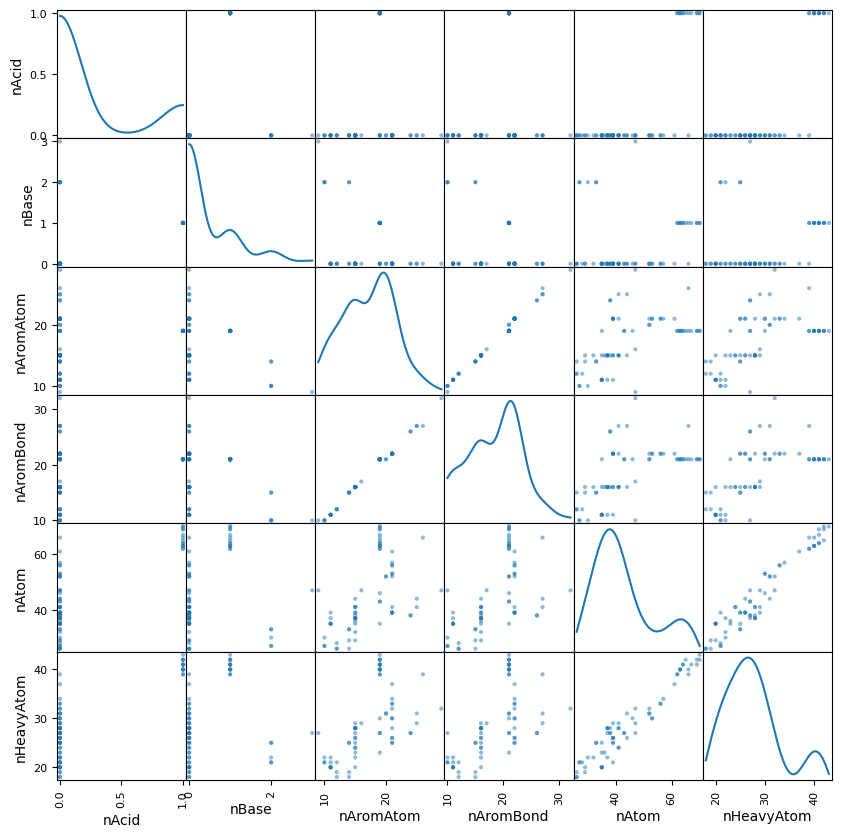

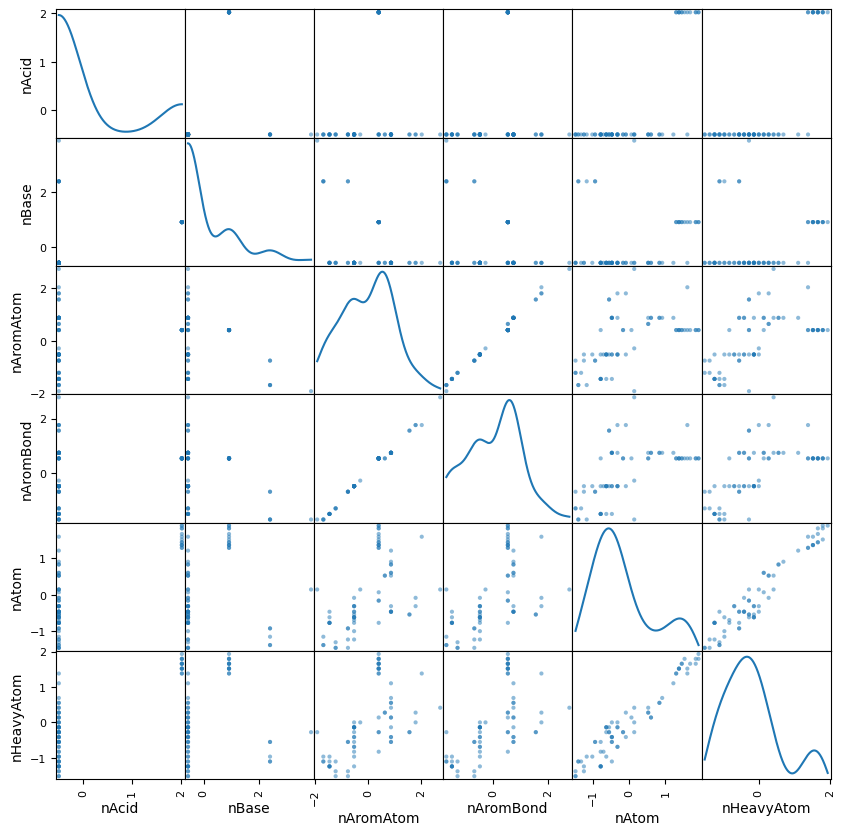

In [34]:
# Estandariza los datos de x_filtered
scaler = StandardScaler()
data_3 = scaler.fit_transform(data_2)
# Crea un nuevo DataFrame con los datos estandarizados y los nombres de las columnas originales
data_3 = pd.DataFrame(data_3, columns=data_2.columns)
#Comparamos los datos antes y despues del escalamiento
# Antes
pd.plotting.scatter_matrix(data_2.iloc[:, :6], figsize=(10, 10), diagonal='kde')
plt.show()
# Después
pd.plotting.scatter_matrix(data_3.iloc[:, :6], figsize=(10, 10), diagonal='kde')
plt.show()

#Select From Model

In [35]:
# prompt: utiliza sklearn, select frommodel para seleccionar las mejores caracteristicas, quiero saber cuales son asi que haz un nuevo dataframe con estas caracteristicas

from sklearn.feature_selection import SelectFromModel

# Crea un modelo de Random Forest
FEAT_SELECTOR_1 = SelectFromModel(estimator=RandomForestRegressor(n_estimators=49, #650 es bueníimo
                                             #criterion='squared_error', #criterion{“squared_error”, “absolute_error”, “poisson”}, default=”squared_error”
                                             #max_depth=50,
                                             #min_samples_split=9, #default=2
                                             min_samples_leaf=3,
                                             #min_weight_fraction_leaf=0.4,
                                             #max_features=100,
                                             #max_leaf_nodes=1000,
                                             #min_impurity_decrease=1E-6,
                                             #bootstrap=False,
                                             #oob_score=False,
                                             #n_jobs=None,
                                             random_state=RANDOM_STATE,
                                             #verbose=0,
                                             #warm_start=True,
                                             #ccp_alpha=0.0,
                                             #max_samples=None
                                                           ),
                                            max_features=22)

# Ajusta el modelo a los datos escalados
FEAT_SELECTOR_1.fit(data_3, y)

# Obtén los nombres de las características seleccionadas
selected_features = data_3.columns[FEAT_SELECTOR_1.get_support()]

# Crea un nuevo DataFrame con las características seleccionadas
data_4 = data_3[selected_features]
print(data_4.shape)
print("Características seleccionadas:")
print(selected_features)

print("\nNuevo DataFrame con características seleccionadas:")
data_4.head()


(71, 22)
Características seleccionadas:
Index(['AATS1m', 'ATSC4c', 'ATSC5m', 'ATSC4i', 'AATSC4c', 'AATSC1v', 'MATS2se',
       'GATS2s', 'GATS3m', 'GATS7m', 'GATS8p', 'C1SP2', 'AXp-0d', 'AXp-5dv',
       'AXp-6dv', 'NdsN', 'CIC2', 'ZMIC1', 'SMR_VSA4', 'SlogP_VSA8', 'n6HRing',
       'JGI7'],
      dtype='object')

Nuevo DataFrame con características seleccionadas:


,AATS1m,ATSC4c,ATSC5m,ATSC4i,AATSC4c,AATSC1v,MATS2se,GATS2s,GATS3m,GATS7m,...,AXp-0d,AXp-5dv,AXp-6dv,NdsN,CIC2,ZMIC1,SMR_VSA4,SlogP_VSA8,n6HRing,JGI7
0,-0.546587,0.801762,3.009641,-1.430179,0.875535,-0.948217,-0.301145,-0.077696,0.064643,0.415933,...,-0.005405,1.213280,1.294481,1.356466,0.593288,-0.959297,0.96971,-0.792053,0.339387,1.662222
1,0.748606,-0.807826,-0.238416,0.195213,-1.352682,-0.299481,0.690499,0.343339,-1.651524,1.283563,...,-0.485086,-2.023375,-1.899230,1.356466,0.135962,-0.875812,0.96971,-1.790566,0.339387,-0.587643
2,-0.497496,-0.691119,1.742986,-0.620831,-0.821525,-0.009872,-0.129001,0.918435,-0.635666,2.308116,...,-1.196033,-1.154849,-1.128599,1.356466,-0.387423,-1.220487,0.96971,-0.792053,-0.755906,-0.533955
3,1.174807,-0.780348,1.490152,1.106916,-1.282252,-0.301173,0.254007,-0.183926,0.728815,-1.581022,...,0.241342,-1.704411,-1.686992,1.356466,-1.060838,-1.109324,0.96971,-1.790566,0.339387,-0.463926
4,1.336281,-1.299051,1.744335,0.891892,-2.277071,-0.119365,0.297496,-0.854871,0.785960,-1.725614,...,0.869881,-1.864366,-1.794334,1.356466,-1.697053,-1.215575,0.96971,-1.790566,0.339387,0.738622


In [36]:
# prompt: has una gráfica que muestre como ha ido cambiando el número de caracteristicas, haslo con plotly, fomdo claro, color verde

import plotly.graph_objects as go

# Datos para la gráfica
etapas = ['Original', 'Variance Threshold', 'Select From Model']
num_caracteristicas = [x.shape[1], data_2.shape[1], data_4.shape[1]]

# Crear la gráfica
fig = go.Figure(data=[go.Bar(x=etapas, y=num_caracteristicas, marker_color= ['green','green','blue'])])

# Configurar el diseño
fig.update_layout(
    title='Reducción del Número de Características',
    xaxis_title='Etapa de Selección',
    yaxis_title='Número de Características',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Mostrar la gráfica
fig.show()


##Análisis de Covarianzas de variables selccionadas

In [37]:
#data_4 = data_4.copy()

In [38]:
# prompt: junta las dos ultmas matricez en una solo celda, comparalas

# Análisis de Covarianzas y Correlación de variables seleccionadas

# Incluye la columna 'activity' en x_selected_df_activity
data_4['activity'] = y

# Calcula la matriz de covarianza
cov_matrix = data_4.cov()

# Calcula la matriz de correlación
corr_matrix = data_4.corr()

# Crea una figura de Plotly para la matriz de covarianza
fig_cov = px.imshow(cov_matrix,
                 x=cov_matrix.columns,
                 y=cov_matrix.columns,
                 color_continuous_scale='Viridis',
                 title='Matriz de Covarianza (Después de SelectFromModel)')

# Crea una figura de Plotly para la matriz de correlación
fig_corr = px.imshow(corr_matrix,
                  x=corr_matrix.columns,
                  y=corr_matrix.columns,
                  color_continuous_scale='Viridis',
                  title='Matriz de Correlación (Después de SelectFromModel)')

# Ajusta el diseño de las figuras
fig_cov.update_layout(
    width=1000,
    height=1000,
    paper_bgcolor='white',
    plot_bgcolor='white',
    font=dict(family="Arial", size=12, color="black")
)

fig_corr.update_layout(
    width=1000,
    height=1000,
    paper_bgcolor='white',
    plot_bgcolor='white',
    font=dict(family="Arial", size=12, color="black")
)

# Muestra las figuras en una sola celda
fig_cov.show()
fig_corr.show()

# Comparación de las matrices
print("La matriz de covarianza muestra la varianza conjunta entre cada par de variables, incluyendo la varianza de cada variable consigo misma.")
print("La matriz de correlación, por otro lado, muestra la fuerza y dirección de la relación lineal entre cada par de variables, normalizada entre -1 y 1.")
print("Observando ambas matrices, podemos identificar patrones de relación entre las variables y la actividad. Por ejemplo, podemos ver qué variables tienen una alta covarianza o correlación con la actividad, lo que podría indicar su importancia en la predicción de la actividad.")


/tmp/ipykernel_4452/1116397963.py:6: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



La matriz de covarianza muestra la varianza conjunta entre cada par de variables, incluyendo la varianza de cada variable consigo misma.
La matriz de correlación, por otro lado, muestra la fuerza y dirección de la relación lineal entre cada par de variables, normalizada entre -1 y 1.
Observando ambas matrices, podemos identificar patrones de relación entre las variables y la actividad. Por ejemplo, podemos ver qué variables tienen una alta covarianza o correlación con la actividad, lo que podría indicar su importancia en la predicción de la actividad.


In [39]:
# prompt: repite la celda anterior pero pon marcas en las gráficas a las alturas -0.1 y 0.1

# Calcula la covarianza y correlación con respecto a 'activity'
covarianzas = data_4.cov()['activity'].drop('activity')
correlaciones = data_4.corr()['activity'].drop('activity')

# Crea un DataFrame para mostrar los resultados
df_grafico = pd.DataFrame({
    'Descriptor': covarianzas.index,
    'Covarianza': covarianzas.values,
    'Correlación': correlaciones.values
})

# Ordena el DataFrame por covarianza en valor absoluto de forma descendente
df_grafico = df_grafico.iloc[abs(df_grafico['Covarianza']).argsort()[::-1]]

# Crea la gráfica de covarianza
fig_cov = go.Figure()
fig_cov.add_trace(go.Bar(
    x=df_grafico['Descriptor'],
    y=df_grafico['Covarianza'],
    marker_color='green',
    name='Covarianza'
))

# Agrega líneas de marca
for y_val in [0]:
    fig_cov.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='solid'))

# Agrega líneas de marca
for y_val in [-0.1, 0.1]:
    fig_cov.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño de la gráfica de covarianza
fig_cov.update_layout(
    title='Covarianza con respecto a Activity ((DESPUÉS DE SelectFromModel))',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Covarianza',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Ordena el DataFrame por correlación en valor absoluto de forma descendente
df_grafico = df_grafico.iloc[abs(df_grafico['Correlación']).argsort()[::-1]]

# Crea la gráfica de correlación
fig_corr = go.Figure()
fig_corr.add_trace(go.Bar(
    x=df_grafico['Descriptor'],
    y=df_grafico['Correlación'],
    marker_color='blue',
    name='Correlación'
))

# Agrega líneas de marca
for y_val in [-0.1, 0.1]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Agrega líneas de marca
for y_val in [0]:
    fig_corr.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='solid')
    )

# Configura el diseño de la gráfica de correlación
fig_corr.update_layout(
    title='Correlación con respecto a Activity (DESPUÉS DE SelectFromModel)',
    xaxis_title='Descriptor',
    yaxis_title='Valor de Correlación',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra las gráficas
fig_cov.show()
fig_corr.show()


In [40]:

# Ordena el DataFrame por índice (nombre del descriptor)
df_grafico = df_grafico.sort_index()

# Crea la figura
fig = go.Figure()

# Agrega la traza de covarianza
fig.add_trace(go.Scatter(
    x=df_grafico['Descriptor'],
    y=df_grafico['Covarianza'],
    mode='lines',
    name='Covarianza',
    line=dict(color='green', width=2)
))

# Agrega la traza de correlación
fig.add_trace(go.Scatter(
    x=df_grafico['Descriptor'],
    y=df_grafico['Correlación'],
    mode='lines',
    name='Correlación',
    line=dict(color='blue', width=2)
))

# Agrega líneas horizontales
for y_val in [-0.6, -0.4, -0.1, 0, 0.1, 0.4]:
    fig.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='dash')
    )

# Agrega líneas horizontales
for y_val in [0]:
    fig.add_shape(
        type='line',
        x0=df_grafico['Descriptor'].iloc[0],
        x1=df_grafico['Descriptor'].iloc[-1],
        y0=y_val,
        y1=y_val,
        line=dict(color='black', width=1, dash='solid')
    )


# Configura el diseño de la figura
fig.update_layout(
    title='Covarianza y Correlación con respecto a Activity',
    xaxis_title='Descriptor',
    yaxis_title='Valor',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra la figura
fig.show()



In [41]:
# prompt: para el ultimo conjunto de datos calcula el histograma de  covarianza y correlación como los de la celda 100

# Crea el histograma de covarianza
fig_cov_hist = go.Figure()
fig_cov_hist.add_trace(go.Histogram(nbinsx=10,
    x=df_grafico['Covarianza'],
    marker_color='green',
    opacity=0.75,
    name='Covarianza'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.1, 0.1]:
    fig_cov_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de covarianza
fig_cov_hist.update_layout(
    title='Histograma de Covarianza con respecto a Activity (Después de SelectFromModel)',
    xaxis_title='Valor de Covarianza',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Crea el histograma de correlación
fig_corr_hist = go.Figure()
fig_corr_hist.add_trace(go.Histogram(nbinsx=12,
    x=df_grafico['Correlación'],
    marker_color='blue',
    opacity=0.75,
    name='Correlación'
))

# Agrega líneas verticales para las marcas
for x_val in [-0.1, 0.1]:
    fig_corr_hist.add_shape(
        type='line',
        x0=x_val,
        x1=x_val,
        y0=0,
        y1=1,
        yref='paper',
        line=dict(color='black', width=1, dash='dash')
    )

# Configura el diseño del histograma de correlación
fig_corr_hist.update_layout(
    title='Histograma de Correlación con respecto a Activity (Después de SelectFromModel)',
    xaxis_title='Valor de Correlación',
    yaxis_title='Frecuencia',
    bargap=0.1,
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# Muestra los histogramas
fig_cov_hist.show()
fig_corr_hist.show()


##Busqueda de características con mayor covarianza con activity

In [42]:
data_4_ = data_4.copy()

#data_4_.insert(0, 'fraction', df_data_['fraction'], allow_duplicates=False)
#data_4_.insert(1, 'fraction', df_info['Cluster_number'], allow_duplicates=False)
data_4_ = pd.concat([df_info, data_4_], axis=1)

In [43]:
# Añadimos tres columna que nos permitirá visualizar la información de los clusters con plotly
data_4_['fraction1'] = data_4_['fraction'].astype('category').cat.codes
data_4_['cn'] = data_4_['Cluster_number'].astype('category').cat.codes
data_4_['cn_s'] = 'Cluster ' + data_4_['Cluster_number'].astype(str)
print(data_4.shape)
data_4_.head()

(71, 23)


,Cmpd,SMILES,Cluster_number,fraction,AATS1m,ATSC4c,ATSC5m,ATSC4i,AATSC4c,AATSC1v,...,CIC2,ZMIC1,SMR_VSA4,SlogP_VSA8,n6HRing,JGI7,activity,fraction1,cn,cn_s
0,Compuesto original,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...,6,train,-0.546587,0.801762,3.009641,-1.430179,0.875535,-0.948217,...,0.593288,-0.959297,0.96971,-0.792053,0.339387,1.662222,5.005513,1,5,Cluster 6
1,Compound 3,O=C1NC2=CC=C([H])C=C2/C1=N\C3=CC=CC(Br)=N3,11,test,0.748606,-0.807826,-0.238416,0.195213,-1.352682,-0.299481,...,0.135962,-0.875812,0.96971,-1.790566,0.339387,-0.587643,4.381642,0,10,Cluster 11
2,Compound 4,O=C1NC2=CC=CC=C2/C1=N\C3=NC4=CC(OCC)=CC=C4S3,12,train,-0.497496,-0.691119,1.742986,-0.620831,-0.821525,-0.009872,...,-0.387423,-1.220487,0.96971,-0.792053,-0.755906,-0.533955,4.114064,1,11,Cluster 12
3,Compound 8,O=C1NC2=CC=C(Br)C=C2/C1=N\C3=CC=CC(F)=N3,11,test,1.174807,-0.780348,1.490152,1.106916,-1.282252,-0.301173,...,-1.060838,-1.109324,0.96971,-1.790566,0.339387,-0.463926,5.012402,0,10,Cluster 11
4,Compound 9,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...,11,test,1.336281,-1.299051,1.744335,0.891892,-2.277071,-0.119365,...,-1.697053,-1.215575,0.96971,-1.790566,0.339387,0.738622,5.047677,0,10,Cluster 11


In [44]:
# prompt: haz una matriz de dispersión de df_pca con plotly,  del descripotr 3 al 8, incluye activity

import plotly.express as px

#________________Por si se enciman los datos_________________________________
# a = data_4_[data_4_['fraction1'].isin([0,1])] #0 es train y 1 es test
# a = data_4_[data_4_['Cluster_number'].isin([8])] # que clusters seleccionamos
a = data_4_
#________________Definimos la gráfica______________________________
# Crea una matriz de dispersión con Plotly
fig = px.scatter_matrix(#data_frame=data_4_,
                        data_frame=a, #Por si se enciman los datos
                        dimensions=[
                                    # 'AATS1m', 'ATSC4c', 'ATSC5m', 'ATSC4i', 'AATSC4c', 'AATSC1v',
                                    # 'MATS2se',
                                    # 'GATS2s', 'GATS3m', 'GATS7m', 'GATS8p',
                                    # 'C1SP2', 'AXp-0d', 'AXp-5dv', 'AXp-6dv',
                                    # 'NdsN', 'CIC2', 'ZMIC1',
                                    'SMR_VSA4', 'SlogP_VSA8',
                                    'n6HRing',
                                    'JGI7',
                                    'activity'
                                    ],
                        #color= 'fraction1',
                        color= 'cn',
                        height=700,
                        width=1400
                        )


#________________Formato________________________________________________________
# fig.update_layout(plot_bgcolor="white", paper_bgcolor="w")  # Set plot background color
fig.update_traces(diagonal_visible=False, marker=dict(line=dict(width=1, color='black'))) #Added marker settings
#_______________________________________________________________________________

app_marker = molplotly.add_molecules(fig=fig,
                                     #_________________________________________
                                     #df=data_4_,
                                     df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                    #  title_col='cn_s',
                                     color_col='fraction1',
                                     fontsize=15, width=350,
                                     )
app_marker.run(port=8860)

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

#PCA.fit()


In [45]:
data_4 = data_4.drop('activity', axis=1)

In [46]:
# Crea un objeto PCA con n componentes
#pca = PCA(n_components=8)
# Ajusta el PCA a los datos
FEAT_SELECTOR2.fit(data_4)
# Transforma los datos usando PCA
x_pca = FEAT_SELECTOR2.transform(data_4)
# Crea un DataFrame con los datos transformados
df_pca = pd.DataFrame(data=x_pca, columns=[f'PC{i+1}' for i in range(FEAT_SELECTOR2.n_components_)])
# Imprime el DataFrame con los componentes principales
df_pca.shape

(71, 8)

In [47]:
data_4_

,Cmpd,SMILES,Cluster_number,fraction,AATS1m,ATSC4c,ATSC5m,ATSC4i,AATSC4c,AATSC1v,...,CIC2,ZMIC1,SMR_VSA4,SlogP_VSA8,n6HRing,JGI7,activity,fraction1,cn,cn_s
0,Compuesto original,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...,6,train,-0.546587,0.801762,3.009641,-1.430179,0.875535,-0.948217,...,0.593288,-0.959297,0.969710,-0.792053,0.339387,1.662222,5.005513,1,5,Cluster 6
1,Compound 3,O=C1NC2=CC=C([H])C=C2/C1=N\C3=CC=CC(Br)=N3,11,test,0.748606,-0.807826,-0.238416,0.195213,-1.352682,-0.299481,...,0.135962,-0.875812,0.969710,-1.790566,0.339387,-0.587643,4.381642,0,10,Cluster 11
2,Compound 4,O=C1NC2=CC=CC=C2/C1=N\C3=NC4=CC(OCC)=CC=C4S3,12,train,-0.497496,-0.691119,1.742986,-0.620831,-0.821525,-0.009872,...,-0.387423,-1.220487,0.969710,-0.792053,-0.755906,-0.533955,4.114064,1,11,Cluster 12
3,Compound 8,O=C1NC2=CC=C(Br)C=C2/C1=N\C3=CC=CC(F)=N3,11,test,1.174807,-0.780348,1.490152,1.106916,-1.282252,-0.301173,...,-1.060838,-1.109324,0.969710,-1.790566,0.339387,-0.463926,5.012402,0,10,Cluster 11
4,Compound 9,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...,11,test,1.336281,-1.299051,1.744335,0.891892,-2.277071,-0.119365,...,-1.697053,-1.215575,0.969710,-1.790566,0.339387,0.738622,5.047677,0,10,Cluster 11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,Compound 11,CC(N=C(NCC)S1)=C1C(/C=C/C2=CC=CC=C2Cl)=O,5,train,-0.803351,-0.422523,-1.730907,-0.971374,-0.349647,-0.056566,...,-0.247295,-1.719609,-0.722621,-1.196731,-0.755906,-0.743263,4.087867,1,4,Cluster 5
67,Compound 13,CC(N=C(NCC)S1)=C1C(/C=C/C2=CC=CC(F)=C2)=O,5,train,-1.106488,-0.355952,-1.299883,-1.289135,-0.230503,-0.043787,...,-0.447159,-1.875293,-0.722621,-1.196731,-0.755906,-1.211677,4.161503,1,4,Cluster 5
68,Compound 15,CC(N=C(NCC)S1)=C1C(/C=C/C2=CC=C(OC)C=C2)=O,5,train,-1.442509,-0.615099,-0.644989,-1.417519,-0.645451,-0.839909,...,-0.118300,-1.814965,-0.722621,-1.196731,-0.755906,-0.686462,4.179135,1,4,Cluster 5
69,Compound 8,CC(N=C(NCC)S1)=C1C(/C=C/C2=CC=CC([N+]([O-])=O)...,5,train,-0.858943,-0.397800,-1.268452,-1.036394,-0.307858,-0.270433,...,-0.593110,-1.760010,-0.722621,-1.196731,-0.755906,-0.442529,4.024048,1,4,Cluster 5


#PCA análisis

In [48]:
# prompt: # prompt: haz una gráfica que expli que la varianza acumulda y varianza individual de cada PC, con plot ly, con un ofndo blanco, pon marcas en el eje de las absisas a la altura de 0.8, 0.9, 0.95, 0.99

import plotly.graph_objects as go

# Calcula la varianza explicada acumulada

cumulative_variance = np.cumsum(FEAT_SELECTOR2.explained_variance_ratio_)
# Crea la figura
fig = go.Figure()

# Agrega la traza de varianza individual
fig.add_trace(go.Bar(
    x=[f'PC{i+1}' for i in range(FEAT_SELECTOR2.n_components_)],
    y=FEAT_SELECTOR2.explained_variance_ratio_,
    name='Varianza Individual'
))

# Agrega la traza de varianza acumulada
fig.add_trace(go.Scatter(
    x=[f'PC{i+1}' for i in range(FEAT_SELECTOR2.n_components_)],
    y=cumulative_variance,
    mode='lines+markers',
    name='Varianza Acumulada',
    line=dict(color='green')
))

# Configura el diseño
fig.update_layout(
    title='Varianza Explicada por Componentes Principales',
    xaxis_title='Componente Principal',
    yaxis_title='Varianza Explicada',
    plot_bgcolor='white',
    xaxis=dict(
        showgrid=True,
        tickmode='linear',
        dtick=1
    ),
    yaxis=dict(
        showgrid=True
    ),
    shapes=[
        dict(
            type='line',
            yref='y', y0=0.8, y1=0.8,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.9, y1=0.9,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.95, y1=0.95,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        ),
        dict(
            type='line',
            yref='y', y0=0.99, y1=0.99,
            xref='paper', x0=0, x1=1,
            line=dict(color='gray', dash='dash')
        )
    ]
)

# Muestra la gráfica
fig.show()


**Necesitamos 9 componentes para explicar el 80 % de la varianza, 13 para explicar el 0.89 %, 18 para el 95 % y 25 para el 0.98%**



El gráfico muestra la varianza explicada por cada componente principal y la varianza acumulada.

El objetivo del análisis de componentes principales (PCA) es encontrar un conjunto más pequeño de variables que expliquen la mayor parte de la varianza en los datos.
Al observar la gráfica, puedes determinar cuántos componentes principales son necesarios para explicar una cantidad suficiente de varianza en los datos.

Por ejemplo, si deseas explicar el 95% de la varianza en los datos, puedes buscar el punto en la línea roja donde la varianza acumulada es igual a 0.95.
El número de componentes principales correspondientes a ese punto es el número de componentes principales que necesitas utilizar.


In [49]:
df_data_

,nAcid,nBase,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,nHetero,nH,...,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2,activity,fraction
0,0,3,9,10,47,27,0,0,9,20,...,405.1093,8.619347,2138,39,146,171,8.361111,5.750000,5.005513,train
1,0,0,12,12,26,18,0,0,5,8,...,300.9851,11.576350,599,26,96,113,5.166667,3.916667,4.381642,test
2,0,0,15,16,36,23,0,0,6,13,...,323.0728,8.974246,1245,35,126,151,6.138889,5.027778,4.114064,train
3,0,0,12,12,26,19,0,0,6,7,...,318.9757,12.268290,693,28,102,120,6.027778,4.083333,5.012402,test
4,0,0,12,12,28,21,0,0,8,7,...,345.9702,12.356080,929,32,112,132,7.138889,4.527778,5.047677,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,0,0,11,11,35,20,0,0,5,15,...,306.0594,8.744553,902,27,98,112,7.166667,4.583333,4.087867,train
67,0,0,11,11,35,20,0,0,5,15,...,290.0889,8.288255,915,26,98,111,7.166667,4.555556,4.161503,train
68,0,0,11,11,39,21,0,0,5,18,...,302.1089,7.746382,1081,28,102,116,7.416667,4.888889,4.179135,train
69,0,0,11,11,37,22,0,0,7,15,...,317.0834,8.569822,1197,30,108,123,8.277778,5.000000,4.024048,train


In [50]:
# prompt: a x_selected_df agregale y = activity

df_pca['activity'] = y

print(df_pca.shape)
df_pca.head(2)


(71, 9)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,activity
0,0.470721,-0.427346,0.203191,0.595311,0.101306,-0.840047,-1.082358,3.540171,5.005513
1,-1.642632,-0.278759,-1.118618,4.517489,-0.399042,1.403408,-0.751234,0.174759,4.381642


In [51]:
# prompt: # prompt: coloca juntas en una misma celda las dos ultimas gráficas de linea continua, uqe se comparen con el eje de las absisas, correlación en color verde y correlación en color azul

# Calcula las covarianzas con respecto a 'activity'
#covarianzas_activity = cov_matrix['activity'].drop('activity')

# Calcula los coeficientes de correlación
covarianzas_activity = df_pca.cov()['activity'].drop('activity')

# Crea un DataFrame para la gráfica de covarianzas
df_covarianzas = pd.DataFrame({
    'Componente Principal': covarianzas_activity.index,
    'Covarianza': covarianzas_activity.values
})

# Calcula los coeficientes de correlación
correlations = df_pca.corr()['activity'].drop('activity')

# Crea un DataFrame para la gráfica de correlaciones
df_correlations = pd.DataFrame({
    'Componente Principal': correlations.index,
    'Correlación': correlations.values
})

# Crea la figura de Plotly con ambas gráficas
fig = go.Figure()

# Agrega la línea de covarianzas
fig.add_trace(go.Scatter(
    x=df_covarianzas['Componente Principal'],
    y=df_covarianzas['Covarianza'],
    mode='lines+markers',
    name='Covarianza',
    line=dict(color='green')
))

# Agrega la línea de correlaciones
fig.add_trace(go.Scatter(
    x=df_correlations['Componente Principal'],
    y=df_correlations['Correlación'],
    mode='lines+markers',
    name='Correlación',
    line=dict(color='blue')
))

# Agrega una línea de referencia en el eje 0
fig.add_shape(
    type='line',
    x0=df_covarianzas['Componente Principal'].iloc[0],
    x1=df_covarianzas['Componente Principal'].iloc[-1],
    y0=0,
    y1=0,
    line=dict(color='black', dash='dash')
)

# Configura el título y etiquetas de los ejes
fig.update_layout(
    title='Covarianzas y Correlaciones de los Componentes Principales con respecto a la Actividad',
    xaxis_title='Componente Principal',
    yaxis_title='Valor',
    plot_bgcolor='white',
    paper_bgcolor='white',
    legend=dict(x=0.8, y=0.1)
)

# Muestra la gráfica
fig.show()


Podemos observar que no todos los PC´s tienen la misma correlación, aunque la covarianza va de mayor a menor, la correlación tiene un comportamiento más variable

In [52]:
# Calcula los valores absolutos del coeficiente de correlación entre los Pcs y la actividad,
# ordena de mayor a menor los valores absolutos y haremos una selección de los descriptores con coeficcientes de correlacción mayor a 0.1

# Calcula los valores absolutos de los coeficientes de correlación
abs_correlations = abs(correlations)
# Ordena los valores absolutos de mayor a menor
sorted_correlations = abs_correlations.sort_values(ascending=False)
# Selecciona los descriptores con coeficientes de correlación mayor a 0.1
selected_descriptors = sorted_correlations[sorted_correlations > 0.1]

print(selected_descriptors)


PC1    0.724686
PC6    0.290036
PC2    0.289373
PC3    0.216229
PC4    0.214356
Name: activity, dtype: float64


In [53]:
# prompt: has un nuevo dataframe con selected descriptors

#_______________DECISIÖN_______________________________________________________
df_selected = df_pca.copy() #podemos trabajar con todos los PCA´s
#__________
#df_selected = df_pca[selected_descriptors.index] #podemos trabajar con los PCA´s seleccionados
#df_selected['activity'] = df_pca['activity']# Agrega la columna 'activity' al nuevo DataFrame
#______________________________________________________________________________



In [54]:
df_pca_ = pd.concat([df_info, df_pca], axis=1)
print(df_pca_.shape)
df_pca_.head()

(71, 13)


,Cmpd,SMILES,Cluster_number,fraction,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,activity
0,Compuesto original,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...,6,train,0.470721,-0.427346,0.203191,0.595311,0.101306,-0.840047,-1.082358,3.540171,5.005513
1,Compound 3,O=C1NC2=CC=C([H])C=C2/C1=N\C3=CC=CC(Br)=N3,11,test,-1.642632,-0.278759,-1.118618,4.517489,-0.399042,1.403408,-0.751234,0.174759,4.381642
2,Compound 4,O=C1NC2=CC=CC=C2/C1=N\C3=NC4=CC(OCC)=CC=C4S3,12,train,-1.887928,-0.694370,-1.508927,3.753081,1.459529,1.667420,-0.201428,2.065033,4.114064
3,Compound 8,O=C1NC2=CC=C(Br)C=C2/C1=N\C3=CC=CC(F)=N3,11,test,-1.140667,-2.400661,0.907809,3.499995,0.117229,-0.436775,-1.695116,-1.362706,5.012402
4,Compound 9,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...,11,test,-0.600798,-3.135306,1.433109,3.969459,-0.760900,-0.204406,-1.040279,-1.726916,5.047677


In [55]:
#df_pca.insert(0, 'fraction', df_data_['fraction'], allow_duplicates=False)

In [56]:
# Añadimos tres columna que nos permitirá visualizar la información de los clusters con plotly
df_pca_['fraction1'] = df_pca_['fraction'].astype('category').cat.codes
df_pca_['cn'] = df_pca_['Cluster_number'].astype('category').cat.codes
df_pca_['cn_s'] = 'Cluster ' + df_pca_['Cluster_number'].astype(str)
print(df_pca_.shape)
df_pca_.head()

(71, 16)


,Cmpd,SMILES,Cluster_number,fraction,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,activity,fraction1,cn,cn_s
0,Compuesto original,O=C(N/1)/C(SC1=N/C2=NC3=CC=C(F)C=C3S2)=C/N4CCN...,6,train,0.470721,-0.427346,0.203191,0.595311,0.101306,-0.840047,-1.082358,3.540171,5.005513,1,5,Cluster 6
1,Compound 3,O=C1NC2=CC=C([H])C=C2/C1=N\C3=CC=CC(Br)=N3,11,test,-1.642632,-0.278759,-1.118618,4.517489,-0.399042,1.403408,-0.751234,0.174759,4.381642,0,10,Cluster 11
2,Compound 4,O=C1NC2=CC=CC=C2/C1=N\C3=NC4=CC(OCC)=CC=C4S3,12,train,-1.887928,-0.694370,-1.508927,3.753081,1.459529,1.667420,-0.201428,2.065033,4.114064,1,11,Cluster 12
3,Compound 8,O=C1NC2=CC=C(Br)C=C2/C1=N\C3=CC=CC(F)=N3,11,test,-1.140667,-2.400661,0.907809,3.499995,0.117229,-0.436775,-1.695116,-1.362706,5.012402,0,10,Cluster 11
4,Compound 9,O=C1NC2=CC=C(Br)C=C2/C1=N/C3=CC([N+]([O-])=O)=...,11,test,-0.600798,-3.135306,1.433109,3.969459,-0.760900,-0.204406,-1.040279,-1.726916,5.047677,0,10,Cluster 11


##Gráficas de PCA

In [57]:
# prompt: haz una matriz de dispersión de df_pca con plotly,  del descripotr 3 al 8, incluye activity

import plotly.express as px

#________________Por si se enciman los datos_________________________________
a = df_pca_
# a = df_pca_[df_pca_['fraction1'].isin([0,1])]
# a = df_pca_[df_pca_['Cluster_number'].isin([2])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
# Crea una matriz de dispersión con Plotly
fig = px.scatter_matrix(data_frame=a,
                         #data_frame=a, #Por si se enciman los datos
                        dimensions=['PC1', 'PC2', 'PC3', 'PC4',
                                   # 'PC5', 'PC6', 'PC7', 'PC8',
                                    'activity'],
                        color= 'fraction',
                        # color= 'cn_s',
                        width = 1500, height = 800 #ajustaos tamaño
                        )
#________________Formato________________________________________________________
# fig.update_layout(plot_bgcolor="white", paper_bgcolor="white")  # Set plot background color
fig.update_traces(diagonal_visible=False, marker=dict(line=dict(width=1, color='black'))) #Added marker settings
#_______________________________________________________________________________

app_marker = molplotly.add_molecules(fig=fig,
                                     #_________________________________________
                                     df=a,
                                     #df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                     #title_col='Activity',
                                     color_col='fraction',
                                    #  color_col='cn_s',
                                     fontsize=15, width=350,
                                     show_coords=False,
                                    caption_cols= ['Cmpd','fraction','activity', 'cn_s','PC1', 'PC2']
                                     )
app_marker.run(port=8825)

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

## PCA loadings

In [58]:
data_4.columns

Index(['AATS1m', 'ATSC4c', 'ATSC5m', 'ATSC4i', 'AATSC4c', 'AATSC1v', 'MATS2se',
       'GATS2s', 'GATS3m', 'GATS7m', 'GATS8p', 'C1SP2', 'AXp-0d', 'AXp-5dv',
       'AXp-6dv', 'NdsN', 'CIC2', 'ZMIC1', 'SMR_VSA4', 'SlogP_VSA8', 'n6HRing',
       'JGI7'],
      dtype='object')

In [59]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(FEAT_SELECTOR2.n_components):
  loadings.append(FEAT_SELECTOR2.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_4.columns)

# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)

In [60]:
# pca_loadings = pca_loadings.drop('activity', axis=1)
pca_loadings

,AATS1m,ATSC4c,ATSC5m,ATSC4i,AATSC4c,AATSC1v,MATS2se,GATS2s,GATS3m,GATS7m,...,AXp-0d,AXp-5dv,AXp-6dv,NdsN,CIC2,ZMIC1,SMR_VSA4,SlogP_VSA8,n6HRing,JGI7
1,0.210386,0.033002,-0.261777,-0.193773,0.054747,-0.193647,0.276267,-0.278869,0.042730,-0.018600,...,0.273811,0.351290,0.356519,-0.193285,-0.227663,-0.216728,-0.191440,-0.275268,-0.094595,0.112375
2,-0.029960,0.389961,-0.102646,-0.152970,0.329032,0.000588,0.072137,-0.199734,-0.282135,0.231272,...,-0.190340,-0.042621,-0.050486,-0.319690,0.039482,0.121761,-0.328395,0.249197,0.395415,-0.015506
3,0.408644,0.168105,0.102669,0.249858,0.274545,0.277693,0.218225,-0.134102,0.326959,0.001180,...,-0.091340,-0.018343,-0.030651,0.144257,-0.313704,0.055769,0.133274,0.098080,0.013925,0.329735
4,0.137867,-0.098550,0.223004,-0.020822,-0.238219,-0.240725,0.090135,-0.137201,-0.119993,0.257879,...,0.008677,-0.294092,-0.288256,0.017979,-0.330770,-0.381636,0.064005,-0.254126,0.137460,0.055207
5,0.044275,0.041808,0.231585,0.408154,0.057947,0.189625,-0.188557,0.149582,0.271520,0.110363,...,-0.268371,0.232413,0.217779,-0.176101,-0.051314,-0.310783,-0.278547,0.028511,-0.096538,-0.233428
6,0.142641,-0.277352,-0.023407,-0.036118,-0.143148,0.231230,0.453717,-0.143876,0.007005,0.236804,...,-0.172777,-0.107284,-0.115152,-0.008163,0.287559,0.227196,-0.101735,0.145481,-0.293585,0.226458
7,-0.255698,-0.099046,-0.267639,0.065318,-0.042904,0.203569,-0.109929,0.369454,-0.003109,0.377212,...,0.314971,-0.099588,-0.072508,-0.256121,-0.192080,-0.227140,-0.111006,0.219468,-0.094495,0.388890
8,-0.175345,0.248202,0.276878,-0.115690,0.229111,-0.164778,-0.135439,0.051698,-0.062834,0.519892,...,0.046351,0.235747,0.221909,0.302112,0.104482,0.155607,0.237532,-0.162541,-0.206463,0.250782


In [61]:
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)

PC1 = 0.2104*AATS1m + 0.0330*ATSC4c + -0.2618*ATSC5m + -0.1938*ATSC4i + 0.0547*AATSC4c + -0.1936*AATSC1v + 0.2763*MATS2se + -0.2789*GATS2s + 0.0427*GATS3m + -0.0186*GATS7m + -0.0683*GATS8p + -0.2270*C1SP2 + 0.2738*AXp-0d + 0.3513*AXp-5dv + 0.3565*AXp-6dv + -0.1933*NdsN + -0.2277*CIC2 + -0.2167*ZMIC1 + -0.1914*SMR_VSA4 + -0.2753*SlogP_VSA8 + -0.0946*n6HRing + 0.1124*JGI7
PC2 = -0.0300*AATS1m + 0.3900*ATSC4c + -0.1026*ATSC5m + -0.1530*ATSC4i + 0.3290*AATSC4c + 0.0006*AATSC1v + 0.0721*MATS2se + -0.1997*GATS2s + -0.2821*GATS3m + 0.2313*GATS7m + 0.1693*GATS8p + 0.1108*C1SP2 + -0.1903*AXp-0d + -0.0426*AXp-5dv + -0.0505*AXp-6dv + -0.3197*NdsN + 0.0395*CIC2 + 0.1218*ZMIC1 + -0.3284*SMR_VSA4 + 0.2492*SlogP_VSA8 + 0.3954*n6HRing + -0.0155*JGI7
PC3 = 0.4086*AATS1m + 0.1681*ATSC4c + 0.1027*ATSC5m + 0.2499*ATSC4i + 0.2745*AATSC4c + 0.2777*AATSC1v + 0.2182*MATS2se + -0.1341*GATS2s + 0.3270*GATS3m + 0.0012*GATS7m + -0.1812*GATS8p + 0.3251*C1SP2 + -0.0913*AXp-0d + -0.0183*AXp-5dv + -0.0307*AXp-6dv + 0

In [62]:
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
figx.show()# Muestra la figura

##  PCA Gráfica de pesos

## Combinacion de PCAs y descriptores

In [65]:
data_4 = data_4.drop(['activity'], axis=1, errors='ignore').copy()
# Concatenar los DataFrames horizontalmente
p = pd.concat([df_pca_, data_4], axis=1)

## PC1 / PC2 vs activity

In [66]:
#Graficar gráfica de dispersión Activity vs PC1

#________________Por si se enciman los datos_________________________________
a= p.copy()
# a = p[p['fraction1'].isin([0,1])]
# a = p[p['Cluster_number'].isin([1,6])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
fig_pca = px.scatter(#data_frame=p,
                     data_frame=a, #Por si se enciman los datos
                     #____coordenadas______________--
                     x='PC1',y='activity',
                     #_____Color_____________
                     color='cn',
                     #color='G',
                     color_discrete_sequence='viridis',
                     #______________________
                     title='Activity vs PC1',
                     width=1050,height=750)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=12)) # Increase marker size
#______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig_pca,
                                     #__________dataframe_____________________
                                     #df=p,
                                     df=a,
                                     #________________________________________
                                     smiles_col='SMILES',
                                     title_col='cn_s',
                                     #__________color_________________________
                                     #color_col='G',
                                     color_col='cn',
                                     #________________________________________
                                     fontsize=20, width=220)
app_marker.run(port=8865)
figx.update_layout(width=1050,height=250)
figx.show()

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [67]:
#Graficar gráfica de dispersión Activity vs PC1

#________________Por si se enciman los datos_________________________________
a = p.copy()
# a = p[p['fraction1'].isin([0,1])]
# a = p[p['Cluster_number'].isin([1,6])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
fig_pca = px.scatter_3d(#data_frame=p,
                     data_frame=a, #Por si se enciman los datos
                     #____coordenadas______________--
                     x='PC1',z='activity', y ='PC2',
                     #_____Color_____________
                     color='cn',
                     #color='G',
                     color_discrete_sequence='viridis',
                     #______________________
                     title='Activity vs PC1',
                     width=1050,height=750)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=12)) # Increase marker size
#______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig_pca,
                                     #__________dataframe_____________________
                                     #df=p,
                                     df=a,
                                     #________________________________________
                                     smiles_col='SMILES',
                                    #  title_col='cn_s',
                                     #__________color_________________________
                                     #color_col='G',
                                     color_col='cn',
                                     #________________________________________
                                     fontsize=20, width=220,
                                    show_coords=False,
                                    caption_cols= ['Cmpd','fraction','activity', 'cn_s','PC1', 'PC2']
                                     )
app_marker.run(port=8060)
figx.update_layout(width=1050,height=250)
figx.show()

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

# Representación de la regresión

## intro

In [68]:
from sklearn.svm import SVR

In [69]:
from sklearn.model_selection import cross_val_score

## SVR 2D

In [70]:
# prompt: de df_pca_svr, escoje solo aquello elementos cintienen df_pca_svr["fraction"] == "train" con isin

dataframe = df_pca_[df_pca_["fraction"].isin(["train"])]
#df_pca_svr_1 = df_pca_.copy()

In [71]:
# prompt: ordena df_pca_ con respecto a la coumn cn_s de maner acendente

df_pca_ = df_pca_.sort_values('cn_s', ascending=True)


In [72]:
pca_name = 'PC1'

# Train an SVR model
X = dataframe[[pca_name]] #combined_df[['PC1']]  # Using only PC1 for 2D visualization
y= dataframe['activity']
#y = pIC50 #combined_df['activity']
REGRESSOR.fit(X, y)
# Create a range of PC1 values for prediction
x_range = np.linspace(X[pca_name].min(), X[pca_name].max(), 100).reshape(-1, 1)

# Predict activity values
y_pred = REGRESSOR.predict(x_range)

# Calculate margins (epsilon)
epsilon = float(REGRESSOR.epsilon)


#_______________por si se encima___________________________________
a = df_pca_.copy()
#a = df_pca_[df_pca_['fraction1'].isin([0])]
#a = df_pca_[df_pca_['Cluster_number'].isin([7])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________

# Create the scatter plot with the SVR regression line
figa = px.scatter(a, x=pca_name, y='activity',
                  title=f'{pca_name} vs Activity with SVR and Margins',
                  #opacity=0.7,
                  #size = 'activity', # added size based on activity
                  #size_max=10,
                  color= 'cn_s',
                  symbol='fraction',
                  hover_data =['Cluster_number'],
                  hover_name = 'cn_s',
                  width=900,height=500) # increased maximum size

figa.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
figa.update_traces(marker=dict(size=12)) # Increase marker size

# Add the SVR regression line (in blue)
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred, mode='lines', name='SVR Prediction', line=dict(color='blue')))

# Add upper and lower margins
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred + epsilon, mode='lines', line=dict(color='gray', dash='dash'), name='Upper Margin'))
figa.add_trace(go.Scatter(x=x_range.flatten(), y=y_pred - epsilon, mode='lines',line=dict(color='gray', dash='dash'), name='Lower Margin'))

# --- Add support vectors ---
support_vectors = dataframe.iloc[REGRESSOR.support_, :]
support_vector_predictions = REGRESSOR.predict(support_vectors[[pca_name]])

# Identify support vectors on the margins
on_margin = np.abs(support_vectors['activity'] - support_vector_predictions) >= (epsilon - 1e-6)  # Using a small tolerance

# Plot support vectors on margins in pink
figa.add_trace(go.Scatter(x=support_vectors.loc[on_margin, pca_name],
                         y=support_vectors.loc[on_margin, 'activity'],
                         mode='markers',
                         marker=dict(size=10,
                                     color='green'
                                     ),
                         name='VS con Error'))

# Plot other support vectors in orange
figa.add_trace(go.Scatter(x=support_vectors.loc[~on_margin, pca_name],
                         y=support_vectors.loc[~on_margin, 'activity'],
                         mode='markers',
                         marker=dict(size=10,
                                     color='purple',
                                     #symbol='+'
                                     ),
                         name='VS activos'))


# Set background color to white
figa.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white'
)


#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=0.0, xanchor="right", x=-.1))



#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-26.02, xanchor="right", x=2.5))
# Muestra la gráfica
#figa.show()
#figx.update_layout(width=1050,height=250)
#figx.show()
if fig is not None:
  print('figa, se creó')

figa, se creó


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but SVR was fitted with feature names



In [73]:
# Create the scatter plot with the SVR regression line
#_______________por si se encima___________________________________
a = df_pca_.copy()
#a = df_pca_[df_pca_['fraction1'].isin([0])]
#a = df_pca_[df_pca_['Cluster_number'].isin([7])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
#________________Definimos la gráfica______________________________
fig = px.scatter(a, x=pca_name, y='activity',
                 title=f'{pca_name} vs Activity with SVR and Margins',
                 #opacity=0.7,
                 #size = 'activity', # added size based on activity
                 #size_max=10,
                 #symbol ='fraction', # Removed to fix grouping mismatch
                 color='cn_s',
                 width=900,height=500
                 ) # increased maximum size
#______________________________________________________________________________
#_______________________________________________________________________________
# Set background color to white
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size

#fig.update_layout(showlegend=False) # This line removes the legend
fig.update_layout(legend=dict(orientation="v", yanchor="bottom", y=0.0, xanchor="right", x=10.0))
#_______________________________________________________________________________
app = molplotly.add_molecules(fig=fig,
                              #__________dataframe_____________________
                              #df=p,
                              df=a,
                              #________________________________________
                              smiles_col='SMILES',
                              # title_col='cn_s',
                              #__________color_________________________
                              color_col='cn_s',
                              #color_col='cn',
                              #________________________________________
                              fontsize=20, width=220)
if app is not None:
  print('app se creó')

app se creó


/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



In [74]:
figa.show()
app.run(port=8060)
figx.update_layout(width=900,height=250)
figx.show()

<IPython.core.display.Javascript object>

In [75]:
# prompt: cuenta cuantos puntos azules, naranjas y rosas hay, en la gráfica de la celda anterior

# Contar puntos azules (todos los puntos de datos)
num_blue_points = len(dataframe)

# Contar puntos naranjas (vectores de soporte en el margen)
num_orange_points = on_margin.sum()

# Contar puntos rosas (otros vectores de soporte)
num_pink_points = (~on_margin).sum()

print("Número de puntos azules:", num_blue_points)
print("Número de puntos naranjas:", num_orange_points)
print("Número de puntos rosas:", num_pink_points)


Número de puntos azules: 49
Número de puntos naranjas: 38
Número de puntos rosas: 4


## SVR 3D

In [76]:
# prompt: en la última gráfica muestra los puntos de apoyo, solo los que tocan los márgenes en color rosa

# Assuming 'combined_df' is your DataFrame with PC1, PC2, and activity columns
PCname1='PC1'
PCname2='PC2'
# Train an SVR model
X = dataframe[[PCname1, PCname2]]  # Using both PC1 and PC2 for 3D visualization
y = dataframe['activity']
#svr = SVR(kernel='rbf', C=10.0, epsilon=0.20)
REGRESSOR.fit(X, y)

# Create a meshgrid of points to predict on
x_range = np.linspace(X[PCname1].min(), X[PCname1].max(), 50)
y_range = np.linspace(X[PCname2].min(), X[PCname2].max(), 50)
xx, yy = np.meshgrid(x_range, y_range)
xy_mesh = np.vstack((xx.ravel(), yy.ravel())).T

# Predict activity values on the meshgrid
z_pred = REGRESSOR.predict(xy_mesh)
z_pred = z_pred.reshape(xx.shape)

# Calculate margins (epsilon)
epsilon = REGRESSOR.epsilon

# Create the 3D scatter plot with the SVR surface
#_______________por si se encima___________________________________
a = df_pca_.copy()
#a = df_pca_[df_pca_['fraction1'].isin([0])]
#a = df_pca_[df_pca_['Cluster_number'].isin([7])] # que clusters seleccionamos

fig_G = px.scatter_3d(a, x=PCname1, y=PCname2, z='activity',
                    title=f'{PCname1} vs {PCname2} vs Activity with SVR, Margins, and Regression Tubes',
                    opacity=1.0, #size='activity', size_max=25,
                      symbol='fraction',
                    color='cn', hover_name='cn_s', hover_data=['activity'],
                      width=900, height=900 )
fig_G.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_G.update_traces(marker=dict(size=12)) # Increase marker size
# Add the SVR surface
fig_G.add_surface(x=xx, y=yy, z=z_pred,
                colorscale='Blues',
                opacity=0.5, name='SVR Prediction')

# --- Add margins as surfaces (in gray) ---
fig_G.add_surface(x=xx, y=yy, z=z_pred + epsilon, showscale=False, opacity=0.1, name='Upper Margin', colorscale='gray_r')
fig_G.add_surface(x=xx, y=yy, z=z_pred - epsilon, showscale=False, opacity=0.1, name='Lower Margin', colorscale='gray_r')

# --- Add support vectors ---
support_vectors = dataframe.iloc[REGRESSOR.support_, :]
support_vector_predictions = REGRESSOR.predict(support_vectors[[PCname1, PCname2]])

# Identify support vectors on the margins
on_margin = np.abs(support_vectors['activity'] - support_vector_predictions) <= epsilon

# Plot support vectors on margins in pink
fig_G.add_trace(go.Scatter3d(x=support_vectors[on_margin][PCname1],
                         y=support_vectors[on_margin][PCname2],
                         z=support_vectors[on_margin]['activity'],
                         mode='markers',
                         marker=dict(size=7, color='pink'),
                         name='VS activos'))

# Plot other support vectors in orange
fig_G.add_trace(go.Scatter3d(x=support_vectors[~on_margin][PCname1],
                         y=support_vectors[~on_margin][PCname2],
                         z=support_vectors[~on_margin]['activity'],
                         mode='markers',
                         marker=dict(size=5, color='orange'),
                         name='VS con error'))


# --- Add regression tubes ---
for i in range(len(df_pca_)):
    x_tube = [df_pca_.iloc[i][PCname1]] * 2
    y_tube = [df_pca_.iloc[i][PCname2]] * 2
    z_tube = [df_pca_.iloc[i]['activity'], REGRESSOR.predict(df_pca_.iloc[[i]][[PCname1, PCname2]])[0]]
   # fig.add_trace(go.Scatter3d(x=x_tube, y=y_tube, z=z_tube, mode='lines',
    #                         line=dict(color='green', width=2), showlegend=False))
#fig.update_layout(showlegend=False) # This line removes the legend
fig_G.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-10.0, xanchor="left", x=0.0))
# Set background color to white
#fig.update_layout(showlegend=False) # This line removes the legend
fig_G.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-10.0, xanchor="left", x=0.0))
# Set background color to white
fig_G.update_layout(plot_bgcolor='white', paper_bgcolor='white')

fig_G.update_traces(marker=dict(line=dict(width=12, color='black')), selector=dict(type='scatter3d'))


fig_G.update_layout(hoverlabel_font_size=20)
fig_G.update_layout(
    plot_bgcolor='gray',
    paper_bgcolor='white'
)
#figx.update_layout(width=1050,height=250)
#figx.show()
#fig_G.show()

if fig_G is not None:
  print('fig_G, se creó')



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but SVR was fitted with feature names



fig_G, se creó


In [77]:
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________
a = df_pca_.copy()
#a = df_pca_[df_pca_svr_1['fraction1'].isin([0,1])]
#a = df_pca_[df_pca_svr_1['cn'].isin([1,2,3,4,5,6,7,8,9,10,11,12,13])]
#________________Definimos la gráfica_______________________________________
fig_ = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=PCname1,
                        y=PCname2,
                        z='activity',
                        #______color________________________________________
                        #color='G',
                        color='cn',
                        #___________________________________________________
                        #symbol=['fraction1'],
                        title=f'Activity vs {PCname1} vs {PCname2}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_.update_traces(marker=dict(size=12)) # Increase marker size
#fig.update_layout(showlegend=False) # This line removes the legend
fig_.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-10.0, xanchor="left", x=0.0))
# Set background color to white


fig_.update_traces(marker=dict(line=dict(width=12, color='black')), selector=dict(type='scatter3d'))


fig_.update_layout(hoverlabel_font_size=20)
#______________________________________________________________________________
app_marker_G = molplotly.add_molecules(fig=fig_,
                                     #___________dataframe__________________
                                     df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                    #  title_col='cn_s',
                                     #____________color_____________________
                                     color_col='cn',
                                     #color_col='G',
                                     #________________________________________
                                     #show_coords=False,
                                    #  symbol_col=['fraction1'],
                                     caption_cols=['Cmpd'],
                                     fontsize=20, width=210)
#app_markerG.run(port=8060)
#figx.show()

if app_marker_G is not None:
  print('app_marker_G, se creó')

app_marker_G, se creó


/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



In [78]:
fig_G.show()
app_marker_G.run(port=8060)
figx.update_layout(width=900,height=250)
figx.show()

<IPython.core.display.Javascript object>

In [79]:
# prompt: dime cuantos puntos azules hay cuauntos rosas y cuantos naranjas  hay en la gráfica anateriror

# Contar puntos azules (todos los puntos de datos)
num_blue_points = len(dataframe)

# Contar puntos naranjas (vectores de soporte que NO están en el margen)
num_orange_points = (~on_margin).sum()

# Contar puntos rosas (vectores de soporte en el margen)
num_pink_points = on_margin.sum()

print("Número de puntos azules:", num_blue_points)
print("Número de puntos naranjas:", num_orange_points)
print("Número de puntos rosas:", num_pink_points)



Número de puntos azules: 49
Número de puntos naranjas: 33
Número de puntos rosas: 8


# Descriptores y PCA

In [80]:
# para crear la matriz de correlación entre PCA y descriptores creamos una variable auxiliar llamada a_
# A a_se le quitaran con a.drop() las columnas que no se les puede calcular la correlación
# a_  puede para por un umbral .isin para seleccionar grupos específicos cn_s

p_ = p.drop(['Cmpd','SMILES','fraction', 'Cluster_number','fraction1','cn','cn_s'], axis=1, errors='ignore')
#a_ = a.drop(['Cmpd','SMILES','fraction', 'Cluster_number','fraction1','cn','cn_s'], axis=1, errors='ignore')

# Calcula la matriz de correlación
corr_matrix = p_.corr()

#corr_matrix = a_.corr()

# Crea la figura con Plotly
fig = px.imshow(corr_matrix, # Changed from p_ to corr_matrix
                 color_continuous_scale='Blues',
                 x=p_.columns,
                 y=p_.columns,
                 text_auto=False  # Quita los números dentro de la matriz
                )

# Ajusta el tamaño de la imagen
fig.update_layout(width=1000, height=800)
fig.add_shape(type="line", x0=8, y0=0, x1=8, y1=len(corr_matrix), line=dict(color="Green", width=2, dash="dashdot"))
fig.add_shape(type="line", x0=0, y0=8, x1=len(corr_matrix), y1=8, line=dict(color="Green", width=2, dash="dashdot"))
# Muestra la figura
fig.show()

In [81]:
# prompt: haz una matriz de dispersión de df_pca con plotly,  del descripotr 3 al 8, incluye activity

import plotly.express as px

#________________Por si se enciman los datos_________________________________
a = p[p['fraction1'].isin([0,1])] #0 es train y 1 es test
#a = p[p['Cluster_number'].isin([1,6])] # que clusters seleccionamos
#________________Definimos la gráfica______________________________
# Crea una matriz de dispersión con Plotly
fig = px.scatter_matrix(#data_frame=data_4_,
                        data_frame=a, #Por si se enciman los datos
                        dimensions=['PC1','PC2',
                                    'ATSC4c', 'ATSC5m', 'ATSC4i',
                                    # 'AATSC4c',#'AATSC5Z', #'AATSC1v',#'MATS4c','MATS1v', 'MATS2se',
                                    #'GATS3Z','GATS7Z','GATS7m','GATS8p',
                                    #'C1SP2',
                                    #'AXp-7dv',
                                    #'NdsN', 'SdsN',
                                    #'CIC1', 'ZMIC1',
                                    #'SMR_VSA4', 'SlogP_VSA8',
                                    #'n6HRing',
                                    'activity'],
                        height= 700, width = 1400,
                        #color= 'fraction1',
                        color= 'cn',
                        #symbol= 'fraction1',
                        #color_discrete_sequence='viridis',
                        )


#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor=px.colors.qualitative.Pastel2[0])  # Set plot background color
fig.update_traces(diagonal_visible=False, marker=dict(line=dict(width=1, color='black'))) #Added marker settings
#_______________________________________________________________________________

app_marker = molplotly.add_molecules(fig=fig,
                                     #_________________________________________
                                     #df=data_4_,
                                     df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                    #  title_col='cn_s',
                                    # color_col='fraction1',
                                     #symbol_col='fraction1',
                                     fontsize=15, width=350,
                                     )
app_marker.run(port=8060)

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>